# European Aviation Access Analysis (Verified Eurostat Data)
This notebook analyzes socioeconomic and spatial disparities in European air travel by dynamically loading and heavily filtering the raw Eurostat CSV files to isolate the correct statistical indicators.

## 1. Setup, Imports, and Data Extraction
The raw Eurostat CSVs contain multiple intersecting variables (e.g., flight frequencies, various household types). We filter them down to:
* **GDP:** Gross domestic product at market prices (Current prices, euro per capita)
* **Gini:** Gini coefficient of equivalised disposable income
* **Participation:** `100 - NM12` (Not flying in 12 months) filtered for total population.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from scipy.optimize import curve_fit
from scipy.stats import linregress
from pathlib import Path

# Set default styling for minimalist charts (Stephen Few principles)
sns.set_theme(style='white', rc={'axes.spines.top': False, 'axes.spines.right': False})

current_dir = Path().resolve()
root_dir = current_dir
while not (root_dir / "datas").exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent

DATA_DIR = root_dir / "datas" / "datas" / "Firsts_questions"

file_air = DATA_DIR / 'Persons by frequency of air travel in the last 12 months.csv'
file_gdp = DATA_DIR /'Gross domestic product (GDP) and main components per capita - annual data.csv'
file_gini =DATA_DIR / 'Gini coefficient of equivalised disposable income by age.csv'

# Countries analyzed in presentation
countries = ["BG", "RO", "HR", "HU", "PL", "SK", "LT", "LV", "EL", "PT", "CZ", "SI", "EE", "IT", "ES", "MT", "CY", "FR", "DE", "BE", "AT", "FI", "NL", "SE", "DK", "LU", "NO", "IE"]

# 1. Process GDP (Latest year available per country)
df_gdp = pd.read_csv(file_gdp)
gdp_clean = df_gdp[(df_gdp['na_item'] == 'B1GQ') & (df_gdp['unit'] == 'CP_EUR_HAB') & (df_gdp['geo'].isin(countries))].sort_values('TIME_PERIOD').groupby('geo').last().reset_index()
gdp_clean = gdp_clean[['geo', 'OBS_VALUE']].rename(columns={'OBS_VALUE': 'GDP'})

# 2. Process GINI (Latest year available per country)
df_gini = pd.read_csv(file_gini)
gini_clean = df_gini[(df_gini['age'] == 'TOTAL') & (df_gini['statinfo'] == 'GINI_HND') & (df_gini['geo'].isin(countries))].sort_values('TIME_PERIOD').groupby('geo').last().reset_index()
gini_clean = gini_clean[['geo', 'OBS_VALUE']].rename(columns={'OBS_VALUE': 'Gini'})

# 3. Process Air Travel - Overall Participation
# 'NM12' = 0 flights. Therefore, 100 - NM12 = 1 or more flights.
df_air = pd.read_csv(file_air)
air_base = df_air[(df_air['frequenc'] == 'NM12') & (df_air['yn_arope'] == 'TOTAL') & (df_air['deg_urb'] == 'TOTAL') & (df_air['hhcomp'] == 'TOTAL') & (df_air['geo'].isin(countries))].sort_values('TIME_PERIOD').groupby('geo').last().reset_index()
air_base['Participation'] = 100 - air_base['OBS_VALUE']
part_clean = air_base[['geo', 'Participation']]

# Merge Macro Data
df_macro = part_clean.merge(gdp_clean, on='geo').merge(gini_clean, on='geo')
print("Macroeconomic data successfully merged. Row count:", len(df_macro))


FileNotFoundError: [Errno 2] No such file or directory: 'Gross domestic product (GDP) and main components per capita - annual data.csv'

## 2. Macroeconomics & Household Capacity (GDP vs. Participation)


In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_macro, x='GDP', y='Participation', color='#3b82f6', s=80, alpha=0.8, edgecolor='w')

# Linear Trend
slope, intercept, r_value, _, _ = linregress(df_macro['GDP'], df_macro['Participation'])
x_lin = np.array([df_macro['GDP'].min(), df_macro['GDP'].max() * 1.05])
plt.plot(x_lin, slope * x_lin + intercept, color='#9ca3af', linestyle='--', linewidth=2, label=f'Linear Trend (r = {r_value:.2f})')

# Log Curve
def log_func(x, a, b): return a * np.log(x) + b
popt, _ = curve_fit(log_func, df_macro['GDP'], df_macro['Participation'])
x_log = np.linspace(df_macro['GDP'].min(), df_macro['GDP'].max() * 1.05, 100)
plt.plot(x_log, log_func(x_log, *popt), color='#ef4444', linewidth=2, label='Saturation Curve (Log)')

for i, row in df_macro.iterrows():
    plt.text(row['GDP'], row['Participation'] + 1.5, row['geo'], ha='center', fontsize=9, color='#4b5563')

plt.title('Air Travel Participation by GDP per Capita', fontsize=14, pad=20)
plt.xlabel('GDP per Capita (€)', fontsize=12)
plt.ylabel('Participation Rate (%)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Income Inequality (Gini Coefficient & K-Means Clustering)


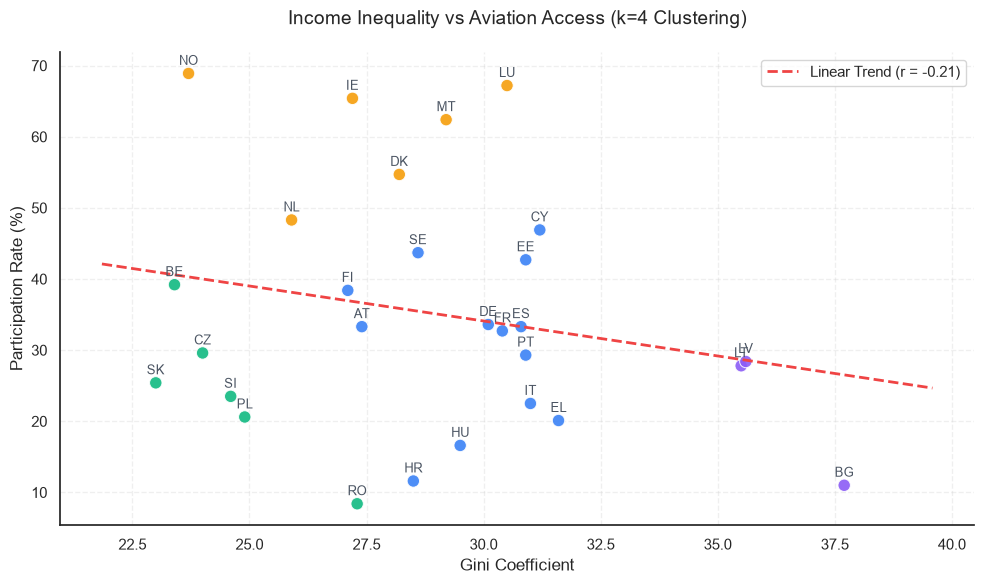

In [3]:
# K-Means Clustering (k=4)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_gini_scaled = (df_macro[['Gini', 'Participation']] - df_macro[['Gini', 'Participation']].mean()) / df_macro[['Gini', 'Participation']].std()
df_macro['Cluster'] = kmeans.fit_predict(df_gini_scaled)

plt.figure(figsize=(10, 6))
cluster_colors = ['#10b981', '#3b82f6', '#8b5cf6', '#f59e0b']
sns.scatterplot(data=df_macro, x='Gini', y='Participation', hue='Cluster', palette=cluster_colors, s=80, alpha=0.9, legend=False)

# Linear Trend
slope_g, intercept_g, r_gini, _, _ = linregress(df_macro['Gini'], df_macro['Participation'])
x_g = np.array([df_macro['Gini'].min() * 0.95, df_macro['Gini'].max() * 1.05])
plt.plot(x_g, slope_g * x_g + intercept_g, color='#ef4444', linestyle='--', linewidth=2, label=f'Linear Trend (r = {r_gini:.2f})')

for i, row in df_macro.iterrows():
    plt.text(row['Gini'], row['Participation'] + 1.2, row['geo'], ha='center', fontsize=9, color='#4b5563')

plt.title('Income Inequality vs Aviation Access (k=4 Clustering)', fontsize=14, pad=20)
plt.xlabel('Gini Coefficient', fontsize=12)
plt.ylabel('Participation Rate (%)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Social Vulnerability Gap (AROPE)
We pivot the data based on `yn_arope` (YES vs NO) to extract the gap per country.


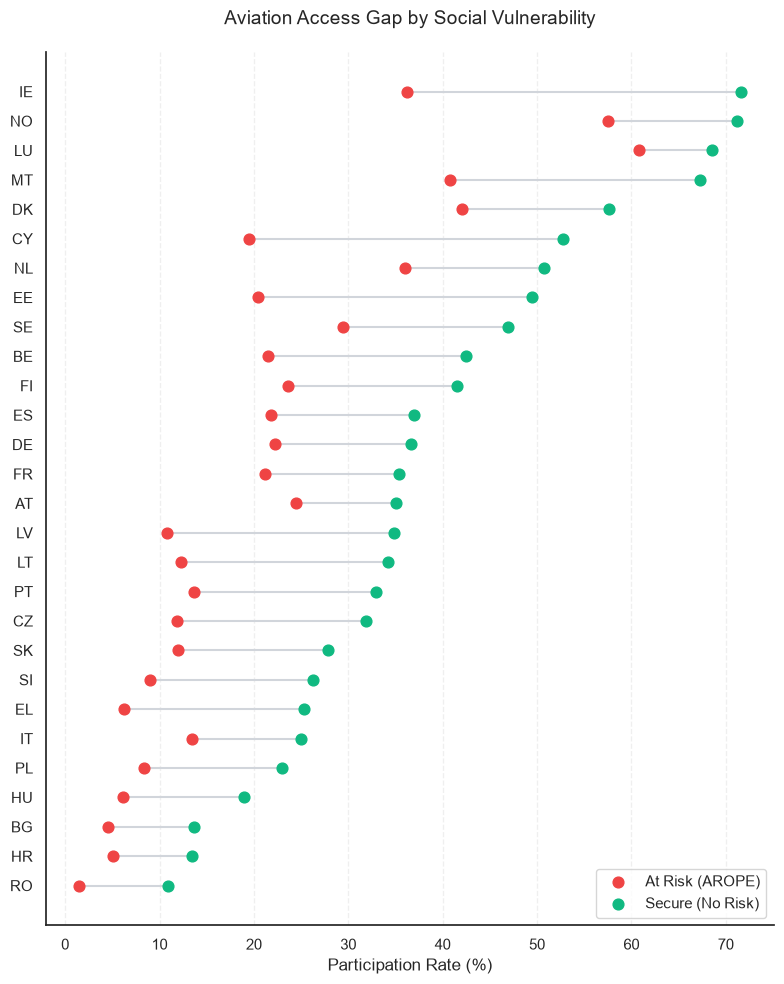

In [4]:
# Process AROPE gap
arope_base = df_air[(df_air['frequenc'] == 'NM12') & (df_air['deg_urb'] == 'TOTAL') & (df_air['hhcomp'] == 'TOTAL') & (df_air['yn_arope'].isin(['YES_AROPE', 'NO_AROPE'])) & (df_air['geo'].isin(countries))].sort_values('TIME_PERIOD').groupby(['geo', 'yn_arope']).last().reset_index()
arope_base['Participation'] = 100 - arope_base['OBS_VALUE']
df_arope_plot = arope_base.pivot(index='geo', columns='yn_arope', values='Participation').reset_index()
df_arope_plot = df_arope_plot.rename(columns={'YES_AROPE': 'risk', 'NO_AROPE': 'norisk'}).sort_values(by='norisk')

plt.figure(figsize=(8, 10))
plt.hlines(y=df_arope_plot['geo'], xmin=df_arope_plot['risk'], xmax=df_arope_plot['norisk'], color='#d1d5db', zorder=1)
plt.scatter(df_arope_plot['risk'], df_arope_plot['geo'], color='#ef4444', label='At Risk (AROPE)', s=60, zorder=2)
plt.scatter(df_arope_plot['norisk'], df_arope_plot['geo'], color='#10b981', label='Secure (No Risk)', s=60, zorder=2)

plt.title('Aviation Access Gap by Social Vulnerability', fontsize=14, pad=20)
plt.xlabel('Participation Rate (%)', fontsize=12)
plt.legend(loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Degree of Urbanisation
We pivot the data based on `deg_urb` (DEG1, DEG2, DEG3) and reshape for a seaborn boxplot.


C:\Users\ahmet\AppData\Local\Temp\ipykernel_26340\2863865922.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=urb_base, x='Urbanisation', y='Participation', jitter=0.15, alpha=0.8, size=6, palette=['#10b981', '#3b82f6', '#8b5cf6'], zorder=2, order=['Cities', 'Towns & Suburbs', 'Rural Areas'])


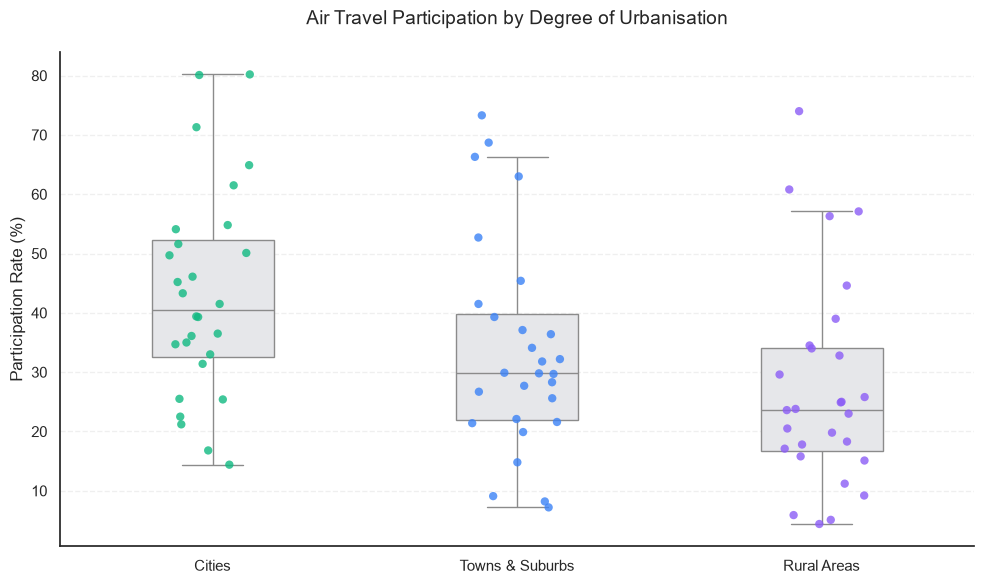

In [5]:
# Process Urbanisation
urb_base = df_air[(df_air['frequenc'] == 'NM12') & (df_air['yn_arope'] == 'TOTAL') & (df_air['hhcomp'] == 'TOTAL') & (df_air['deg_urb'].isin(['DEG1', 'DEG2', 'DEG3'])) & (df_air['geo'].isin(countries))].sort_values('TIME_PERIOD').groupby(['geo', 'deg_urb']).last().reset_index()
urb_base['Participation'] = 100 - urb_base['OBS_VALUE']

# Map DEG codes to readable labels
deg_map = {'DEG1': 'Cities', 'DEG2': 'Towns & Suburbs', 'DEG3': 'Rural Areas'}
urb_base['Urbanisation'] = urb_base['deg_urb'].map(deg_map)

plt.figure(figsize=(10, 6))
sns.boxplot(data=urb_base, x='Urbanisation', y='Participation', width=0.4, showfliers=False, color='#e5e7eb', zorder=1, order=['Cities', 'Towns & Suburbs', 'Rural Areas'])
sns.stripplot(data=urb_base, x='Urbanisation', y='Participation', jitter=0.15, alpha=0.8, size=6, palette=['#10b981', '#3b82f6', '#8b5cf6'], zorder=2, order=['Cities', 'Towns & Suburbs', 'Rural Areas'])

plt.title('Air Travel Participation by Degree of Urbanisation', fontsize=14, pad=20)
plt.ylabel('Participation Rate (%)', fontsize=12)
plt.xlabel('')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
